<a href="https://colab.research.google.com/github/yumi-28/linear_ALgebra_homework/blob/main/%EC%84%A0%ED%98%95%EB%8C%80%EC%88%98%ED%95%99_%EC%B1%8C%EB%A6%B0%EC%A7%80.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

라이브러리 설정

In [552]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000  # 그림판 크기
LEN = 100   # 처음 사각형의 크기

축 그리기 및 사각형 그리기 + 삼각형

> 인용구 추가



In [553]:
def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)  # x-axis line
  ax.axvline(0, color='black', alpha=0.3)  # y-axis line
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')  # 정사각형 모양으로 backboard 그리기

In [554]:
def draw_triangle(ax, p1, p2, p3, color = "blue"):
  my_polygon = Polygon([p1, p2, p3],color = color)
  ax.add_patch(my_polygon)

In [555]:
def draw_rectangle(ax, p1, p2, p3, p4,color = "blue"):
  my_polygon = Polygon([p1, p2, p3, p4],color = color)
  ax.add_patch(my_polygon)

변환구현

In [556]:
# 점 p를 x축 방향으로 dx만큼, y축 방향으로 dy만큼 이동시킨 점 q를 구할 것
# q = T(dx, dy) p1
def translate(p, dx, dy):
  # 1. 동차좌표계 (homogeneous coordinate)으로 변환
  hp = np.array([p[0], p[1], 1.0])

  # 2. 이동 변환 행렬 생성
  m = np.array([[1.0, 0.0, dx], [0.0, 1.0, dy], [0.0, 0.0, 1.0]])

  # 3. 행렬과 벡터의 곱
  q = np.dot(m, hp)  # (3,3) x (3,1) -> (3,1)
  #print(q)

  # 4. 2차원 좌표계로 변환
  q = np.array([q[0], q[1]])
  return q

In [557]:
def scale(p,sx,sy):
  hp = np.array([p[0], p[1], 1.0]) #동차좌표계로 변환

  m = np.array([[sx, 0.0, 0.0], [0.0, sy, 0.0], [0.0, 0.0, 1.0]])  #크기 변환 행렬 생성

  q = np.dot(m, hp)  #행렬과 벡터 곱
  q = np.array([q[0], q[1]])  #2차원 좌표계로 변환
  return q

In [558]:
def rotate(p,theta):
  hp = np.array([p[0],p[1],1.0])

  m = np.array([[np.cos(theta), -np.sin(theta), 0.0], [np.sin(theta), np.cos(theta), 0.0], [0.0, 0.0, 1.0]])

  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q

In [559]:
def shear_x(p, sx):
  hp = np.array([p[0], p[1], 1.0])

  m = np.array([[1.0, sx, 0.0], [0.0, 1.0, 0.0], [0.0, 0.0, 1.0]])

  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q

In [560]:
def shear_y(p, sy):
  hp = np.array([p[0], p[1], 1.0])

  m = np.array([[1.0, 0.0, 0.0], [sy, 1.0,0.0],[0.0,0.0,1.0]])

  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q

파트 그리기


In [561]:
def draw_head(ax,p1,p2,p3,p4):
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,7,5)
  q2 = scale(q2,7,5)
  q3 = scale(q3,7,5)
  q4 = scale(q4,7,5)

  q1 = translate(q1,0,500)
  q2 = translate(q2,0,500)
  q3 = translate(q3,0,500)
  q4 = translate(q4,0,500)

  draw_rectangle(ax,q1,q2,q3,q4,color = "steelblue")

def draw_eye(ax,p1,p2,p3,p4):
  # 왼쪽 눈
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,0.9,0.9)
  q2 = scale(q2,0.9,0.9)
  q3 = scale(q3,0.9,0.9)
  q4 = scale(q4,0.9,0.9)

  q1 = translate(q1,-150,560)
  q2 = translate(q2,-150,560)
  q3 = translate(q3,-150,560)
  q4 = translate(q4,-150,560)

  draw_rectangle(ax,q1,q2,q3,q4,color = "yellow")

  # 오른쪽 눈 (왼쪽 눈과 x축 방향만 반대)
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,0.9,0.9)
  q2 = scale(q2,0.9,0.9)
  q3 = scale(q3,0.9,0.9)
  q4 = scale(q4,0.9,0.9)

  q1 = translate(q1,150,560)
  q2 = translate(q2,150,560)
  q3 = translate(q3,150,560)
  q4 = translate(q4,150,560)

  draw_rectangle(ax,q1,q2,q3,q4,color = "yellow")

def draw_neck(ax,p1,p2,p3,p4):
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,1.7,0.6)
  q2 = scale(q2,1.7,0.6)
  q3 = scale(q3,1.7,0.6)
  q4 = scale(q4,1.7,0.6)

  q1 = translate(q1,0,220)
  q2 = translate(q2,0,220)
  q3 = translate(q3,0,220)
  q4 = translate(q4,0,220)

  draw_rectangle(ax,q1,q2,q3,q4,color = "midnightblue")

def draw_body(ax,p1,p2,p3,p4):
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,4.5,5.5)
  q2 = scale(q2,4.5,5.5)
  q3 = scale(q3,4.5,5.5)
  q4 = scale(q4,4.5,5.5)

  q1 = translate(q1,0,-70)
  q2 = translate(q2,0,-70)
  q3 = translate(q3,0,-70)
  q4 = translate(q4,0,-70)

  draw_rectangle(ax,q1,q2,q3,q4,color="steelblue")

def draw_left_arm(ax,p1,p2,p3,p4):
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  # 세로로 긴 팔 모양 (120 x 400)
  q1 = scale(q1,1.2,4.0)
  q2 = scale(q2,1.2,4.0)
  q3 = scale(q3,1.2,4.0)
  q4 = scale(q4,1.2,4.0)

  # 몸통(x -225~225) 왼쪽 옆으로 이동
  q1 = translate(q1,-310,0)
  q2 = translate(q2,-310,0)
  q3 = translate(q3,-310,0)
  q4 = translate(q4,-310,0)

  draw_rectangle(ax,q1,q2,q3,q4,color="midnightblue")

def draw_right_arm(ax,p1,p2,p3,p4):
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,1.2,4.0)
  q2 = scale(q2,1.2,4.0)
  q3 = scale(q3,1.2,4.0)
  q4 = scale(q4,1.2,4.0)

  # 왼팔과 x축 방향만 반대
  q1 = translate(q1,310,0)
  q2 = translate(q2,310,0)
  q3 = translate(q3,310,0)
  q4 = translate(q4,310,0)

  draw_rectangle(ax,q1,q2,q3,q4,color="midnightblue")

def draw_left_leg(ax,p1,p2,p3,p4):
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  # 150 x 300, 몸통 아래(y -345)에 맞닿게
  q1 = scale(q1,1.5,3.0)
  q2 = scale(q2,1.5,3.0)
  q3 = scale(q3,1.5,3.0)
  q4 = scale(q4,1.5,3.0)

  q1 = translate(q1,-120,-495)
  q2 = translate(q2,-120,-495)
  q3 = translate(q3,-120,-495)
  q4 = translate(q4,-120,-495)

  draw_rectangle(ax,q1,q2,q3,q4,color="midnightblue")

def draw_right_leg(ax,p1,p2,p3,p4):
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,1.5,3.0)
  q2 = scale(q2,1.5,3.0)
  q3 = scale(q3,1.5,3.0)
  q4 = scale(q4,1.5,3.0)

  q1 = translate(q1,120,-495)
  q2 = translate(q2,120,-495)
  q3 = translate(q3,120,-495)
  q4 = translate(q4,120,-495)

  draw_rectangle(ax,q1,q2,q3,q4,color="midnightblue")


def draw_antenna(ax,p1,p2,p3,p4):
  # 안테나 막대
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,0.15,1.2)
  q2 = scale(q2,0.15,1.2)
  q3 = scale(q3,0.15,1.2)
  q4 = scale(q4,0.15,1.2)

  q1 = translate(q1,0,810)
  q2 = translate(q2,0,810)
  q3 = translate(q3,0,810)
  q4 = translate(q4,0,810)

  draw_rectangle(ax,q1,q2,q3,q4,color="dimgray")

  #안테나 구슬
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,0.8,0.8)
  q2 = scale(q2,0.8,0.8)
  q3 = scale(q3,0.8,0.8)
  q4 = scale(q4,0.8,0.8)

  q1 = rotate(q1,np.pi/4)
  q2 = rotate(q2,np.pi/4)
  q3 = rotate(q3,np.pi/4)
  q4 = rotate(q4,np.pi/4)

  q1 = translate(q1,0,900)
  q2 = translate(q2,0,900)
  q3 = translate(q3,0,900)
  q4 = translate(q4,0,900)

  draw_rectangle(ax,q1,q2,q3,q4,color="red")

def draw_pupil(ax,p1,p2,p3,p4):
  # 왼쪽 눈동자
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,0.35,0.35)
  q2 = scale(q2,0.35,0.35)
  q3 = scale(q3,0.35,0.35)
  q4 = scale(q4,0.35,0.35)

  q1 = translate(q1,-150,560)
  q2 = translate(q2,-150,560)
  q3 = translate(q3,-150,560)
  q4 = translate(q4,-150,560)

  draw_rectangle(ax,q1,q2,q3,q4,color="black")

  # 오른쪽 눈동자
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,0.35,0.35)
  q2 = scale(q2,0.35,0.35)
  q3 = scale(q3,0.35,0.35)
  q4 = scale(q4,0.35,0.35)

  q1 = translate(q1,150,560)
  q2 = translate(q2,150,560)
  q3 = translate(q3,150,560)
  q4 = translate(q4,150,560)

  draw_rectangle(ax,q1,q2,q3,q4,color="black")

def draw_mouth(ax,p1,p2,p3,p4):
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,3.0,0.3)
  q2 = scale(q2,3.0,0.3)
  q3 = scale(q3,3.0,0.3)
  q4 = scale(q4,3.0,0.3)

  q1 = translate(q1,0,380)
  q2 = translate(q2,0,380)
  q3 = translate(q3,0,380)
  q4 = translate(q4,0,380)

  draw_rectangle(ax,q1,q2,q3,q4,color="midnightblue")

def draw_chest_panel(ax,p1,p2,p3,p4):
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,2.5,2.5)
  q2 = scale(q2,2.5,2.5)
  q3 = scale(q3,2.5,2.5)
  q4 = scale(q4,2.5,2.5)

  q1 = translate(q1,0,50)
  q2 = translate(q2,0,50)
  q3 = translate(q3,0,50)
  q4 = translate(q4,0,50)

  draw_rectangle(ax,q1,q2,q3,q4,color="midnightblue")

def draw_button(ax,p1,p2,p3,p4):
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,0.8,0.8)
  q2 = scale(q2,0.8,0.8)
  q3 = scale(q3,0.8,0.8)
  q4 = scale(q4,0.8,0.8)

  q1 = rotate(q1,np.pi/4)
  q2 = rotate(q2,np.pi/4)
  q3 = rotate(q3,np.pi/4)
  q4 = rotate(q4,np.pi/4)

  q1 = translate(q1,0,50)
  q2 = translate(q2,0,50)
  q3 = translate(q3,0,50)
  q4 = translate(q4,0,50)

  draw_rectangle(ax,q1,q2,q3,q4,color="orange")

def draw_left_hand(ax,p1,p2,p3,p4):
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,1.5,1.5)
  q2 = scale(q2,1.5,1.5)
  q3 = scale(q3,1.5,1.5)
  q4 = scale(q4,1.5,1.5)


  q1 = translate(q1,-310,-250)
  q2 = translate(q2,-310,-250)
  q3 = translate(q3,-310,-250)
  q4 = translate(q4,-310,-250)

  draw_rectangle(ax,q1,q2,q3,q4,color="steelblue")

def draw_right_hand(ax,p1,p2,p3,p4):
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,1.5,1.5)
  q2 = scale(q2,1.5,1.5)
  q3 = scale(q3,1.5,1.5)
  q4 = scale(q4,1.5,1.5)

  q1 = translate(q1,310,-250)
  q2 = translate(q2,310,-250)
  q3 = translate(q3,310,-250)
  q4 = translate(q4,310,-250)

  draw_rectangle(ax,q1,q2,q3,q4,color="steelblue")

def draw_left_foot(ax,p1,p2,p3,p4):
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)


  q1 = scale(q1,2.2,0.6)
  q2 = scale(q2,2.2,0.6)
  q3 = scale(q3,2.2,0.6)
  q4 = scale(q4,2.2,0.6)

  q1 = translate(q1,-140,-675)
  q2 = translate(q2,-140,-675)
  q3 = translate(q3,-140,-675)
  q4 = translate(q4,-140,-675)

  draw_rectangle(ax,q1,q2,q3,q4,color="steelblue")

def draw_right_foot(ax,p1,p2,p3,p4):
  q1 = translate(p1,-LEN/2,-LEN/2)
  q2 = translate(p2,-LEN/2,-LEN/2)
  q3 = translate(p3,-LEN/2,-LEN/2)
  q4 = translate(p4,-LEN/2,-LEN/2)

  q1 = scale(q1,2.2,0.6)
  q2 = scale(q2,2.2,0.6)
  q3 = scale(q3,2.2,0.6)
  q4 = scale(q4,2.2,0.6)

  q1 = translate(q1,140,-675)
  q2 = translate(q2,140,-675)
  q3 = translate(q3,140,-675)
  q4 = translate(q4,140,-675)

  draw_rectangle(ax,q1,q2,q3,q4,color="steelblue")

In [562]:
def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_antenna(ax,p1,p2,p3,p4)
  draw_head(ax,p1,p2,p3,p4)
  draw_eye(ax,p1,p2,p3,p4)
  draw_pupil(ax,p1,p2,p3,p4)
  draw_mouth(ax,p1,p2,p3,p4)
  draw_neck(ax,p1,p2,p3,p4)
  draw_left_leg(ax,p1,p2,p3,p4)
  draw_right_leg(ax,p1,p2,p3,p4)
  draw_left_foot(ax,p1,p2,p3,p4)
  draw_right_foot(ax,p1,p2,p3,p4)
  draw_body(ax,p1,p2,p3,p4)
  draw_chest_panel(ax,p1,p2,p3,p4)
  draw_button(ax,p1,p2,p3,p4)
  draw_left_arm(ax,p1,p2,p3,p4)
  draw_right_arm(ax,p1,p2,p3,p4)
  draw_left_hand(ax,p1,p2,p3,p4)
  draw_right_hand(ax,p1,p2,p3,p4)

main

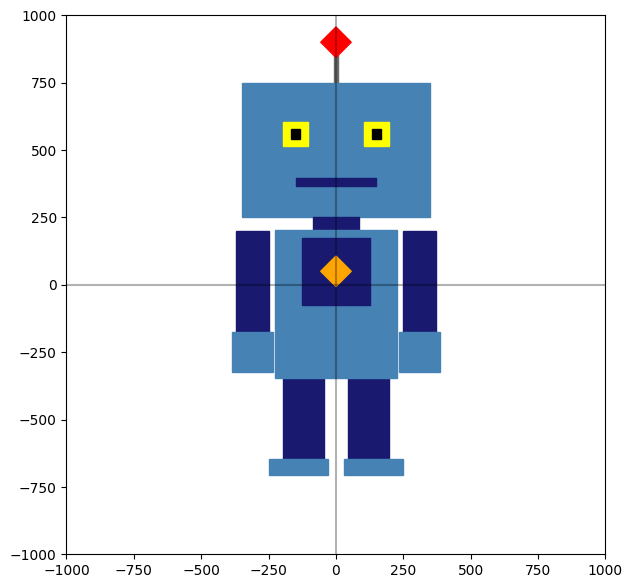

In [563]:
# 그림판 선언 및 크기 설정
fig, ax = plt.subplots(figsize=(7,7))

# 축 그리기
draw_axis(ax)

# 물체 그리기
draw_object(ax)

plt.show()